# Final Technical Report

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import math

## Section 1: Battery Voltage Measurement

### Methods
For evaluating the battery voltage measurment, an array of voltages between 0 and 3V was supplied to the battery pin, representative of a battery's charge. The input value was swept in 250 mV increments. At each input voltage, the LOG_INF() statement, bluetooth reported battery percentage, and oscilliscope defined duty cycle of the PWM controlled LED output were recorded. The cursors were used on the oscilliscope to measure duty cycle. After these values were recorded, a linear regression was calculated alongside the data, and the 95% confidence interval of the slope and intercept were calculated.

In [16]:
# Load the data
df = pd.read_csv("final_battery_data.csv")

# Display the full data table
print("\nFull Data Table:")
print(df.to_markdown(index=False, numalign="left", stralign="left"))


Full Data Table:
| Supply Voltage (mV)   | LOG_INF Voltage (mV)   | LOG_INF Percent of Battery (%)   | BLE Percent of Battery (%)   | Scope Duty Cycle (% on)   |
|:----------------------|:-----------------------|:---------------------------------|:-----------------------------|:--------------------------|
| 0                     | 0                      | 0                                | 0                            | 0                         |
| 250                   | 245                    | 6                                | 6                            | 6.9                       |
| 500                   | 488                    | 13                               | 13                           | 17.3                      |
| 750                   | 747                    | 20                               | 20                           | 23.5                      |
| 1000                  | 996                    | 26                               | 26                        

In [17]:
def run_regression_analysis_scipy(df, x_col, y_col, alpha=0.05):
    
    print(f"\n========================================================")
    print(f"Regression Analysis: {y_col} (Y) vs {x_col} (X)")
    print(f"========================================================")
    
    X = df[x_col]
    Y = df[y_col]
    N = len(X)  
    
    #Perform Linear Regression using SciPy
    slope, intercept, r_value, p_value, std_err_slope = stats.linregress(X, Y)
    r_squared = r_value**2
    
    # calculate standard error of intercept
    ss_x = np.sum((X - np.mean(X))**2)
    y_pred_rse = intercept + slope * X
    residuals_rse = Y - y_pred_rse
    rse = math.sqrt(np.sum(residuals_rse**2) / (N - 2))
    std_err_intercept = rse * math.sqrt((1/N) + (np.mean(X)**2 / ss_x))

    # Calculate 95% Confidence Intervals
    df_fit = N - 2
    t_crit = stats.t.ppf(1 - alpha/2, df_fit)
    
    ci_slope_lower = slope - t_crit * std_err_slope
    ci_slope_upper = slope + t_crit * std_err_slope
    
    ci_intercept_lower = intercept - t_crit * std_err_intercept
    ci_intercept_upper = intercept + t_crit * std_err_intercept

    #Print the Linear Regression Equation and CIs
    equation = f"{y_col} = {intercept:0.4f} + {slope:0.4e} * {x_col}"
    print(f"\nLinear Regression Equation (R² = {r_squared:0.4f}):")
    print(equation)
    print("\n95% Confidence Intervals (using SciPy's t-distribution):")
    print(f"| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |")
    print(f"|:----------|:------------|:----------------|:----------------|")
    print(f"| Intercept | {intercept:0.4f}  | {ci_intercept_lower:0.4f}      | {ci_intercept_upper:0.4f}      |")
    print(f"| Slope     | {slope:0.4e} | {ci_slope_lower:0.4e}   | {ci_slope_upper:0.4e}   |")

    # 5. Plot the data and regression line
    plt.figure(figsize=(10, 6))
    

    plt.scatter(X, Y, label="Data Points", color='blue', marker='o')
    X_range = np.linspace(X.min(), X.max(), 100)
    Y_pred = intercept + slope * X_range
    plt.plot(X_range, Y_pred, color='red', linestyle='-', label=f'Regression Line\n$Y = {intercept:0.4f} + {slope:0.4e}X$')
    plt.title(f'Linear Regression: {y_col} vs {x_col}')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='best')


Regression Analysis: LOG_INF Percent of Battery (%) (Y) vs Supply Voltage (mV) (X)

Linear Regression Equation (R² = 0.9937):
LOG_INF Percent of Battery (%) = -4.0879 + 3.4418e-02 * Supply Voltage (mV)

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | -4.0879  | -7.2900      | -0.8858      |
| Slope     | 3.4418e-02 | 3.2606e-02   | 3.6229e-02   |


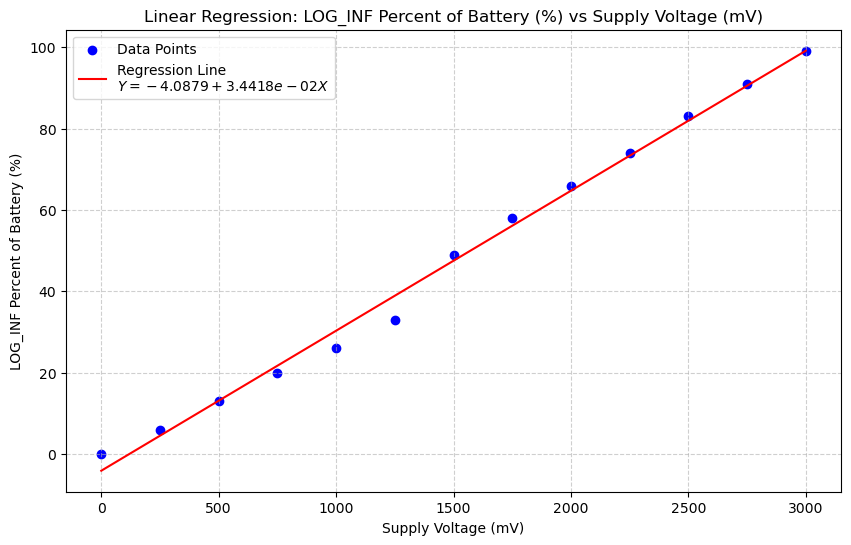

In [18]:
# Supply Voltage vs LOG_INF Percent (LOG_INF Output)
X_COL_1 = 'Supply Voltage (mV)'
Y_COL_1 = 'LOG_INF Percent of Battery (%)'
run_regression_analysis_scipy(df, X_COL_1, Y_COL_1)


Regression Analysis: BLE Percent of Battery (%) (Y) vs Supply Voltage (mV) (X)

Linear Regression Equation (R² = 0.9937):
BLE Percent of Battery (%) = -4.0879 + 3.4418e-02 * Supply Voltage (mV)

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | -4.0879  | -7.2900      | -0.8858      |
| Slope     | 3.4418e-02 | 3.2606e-02   | 3.6229e-02   |


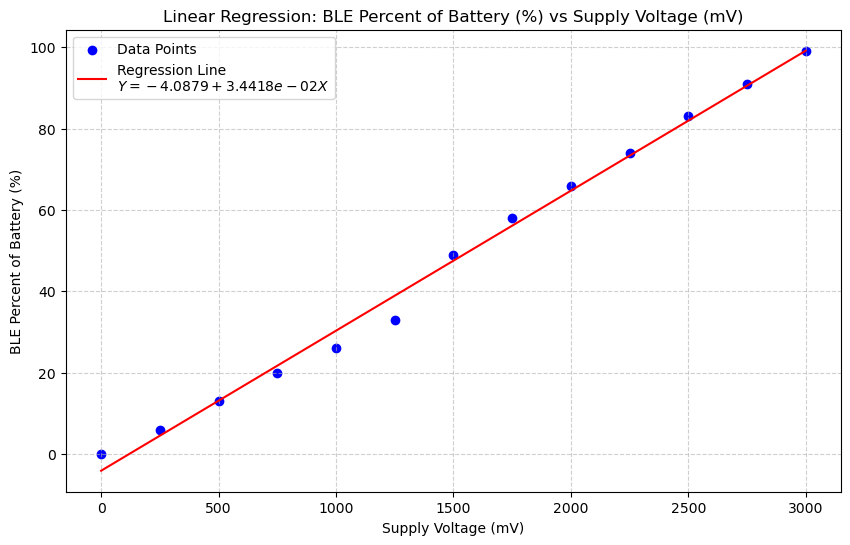

In [19]:
#  Supply Voltage vs BLE Percent (nRF Connect app) 
X_COL_2 = 'Supply Voltage (mV)'
Y_COL_2 = 'BLE Percent of Battery (%)'
run_regression_analysis_scipy(df, X_COL_2, Y_COL_2)


Regression Analysis: Scope Duty Cycle (% on) (Y) vs Supply Voltage (mV) (X)

Linear Regression Equation (R² = 0.9984):
Scope Duty Cycle (% on) = -1.2036 + 3.3416e-02 * Supply Voltage (mV)

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | -1.2036  | -2.7553      | 0.3481      |
| Slope     | 3.3416e-02 | 3.2538e-02   | 3.4294e-02   |


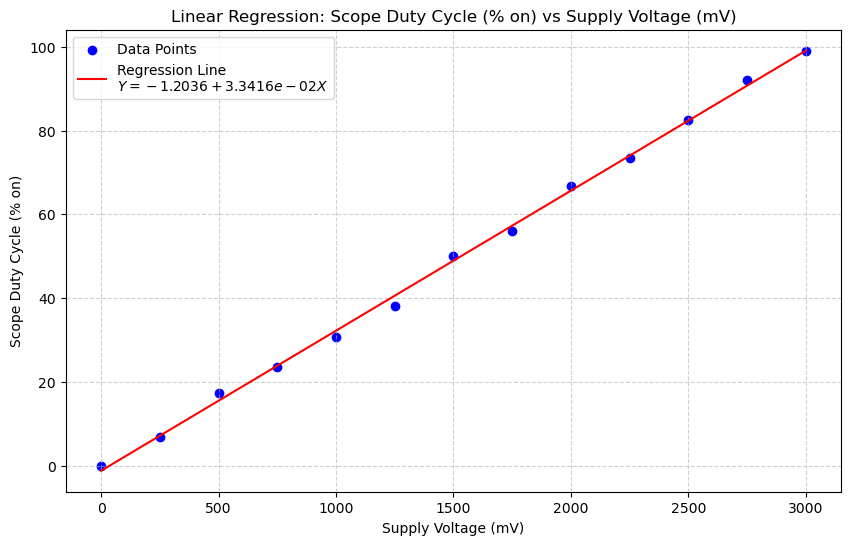

In [20]:
#Supply Voltage vs Scope Duty Cycle (Oscilloscope Measurement)
X_COL_3 = 'Supply Voltage (mV)'
Y_COL_3 = 'Scope Duty Cycle (% on)'
run_regression_analysis_scipy(df, X_COL_3, Y_COL_3)

### Discussion

Across the board, the linear regression analysis shows a very strong, highly linear relationship between the input supply voltage and all three measured battery level indicators (LOG,_INF, BLE, and Scope Duty Cycle). The R^2 values ranged from 0.9937 to 0.9984, indicating a highly linear relationship, which is what we want. The scope duty cycle shows the best fit with an R squared of 0.9984, suggesting that the PWM mechanism used is precise. The R squared of the LOG_INF and BLE have the same fit (R squared equals 0.9937), confirming that the BLE app simply mirrors the value calculated for the LOG_INF statement.

## Section 2: ECG Heart Rate Measurement

### Methods

To calculate HR, I analyze each differential ADC buffer to look for QRS peaks by checking whether the absolute ECG voltage reading rises above a defined threshold (around 450 mV, given we are dealing with 1 V Peak-to-Peak). When the voltage crosses that threshold, I treat it as a potential heartbeat, but I only accept it if it occurs outside a refractory period, which I derive from the maximum expected heart rate of 200 BPM. This prevents double-counting the same QRS complex. Whenever I detect a valid peak, I compute an instantaneous heart rate based on the time difference from the previous accepted peak, and I clamp that BPM value to a physiological range of 40–200 BPM. If no peak is detected for a buffer, I report 0 for that cycle, meaning no beat was found. As the device runs, I accumulate the valid instantaneous BPM values, and whenever the state machine needs to output a heart rate, I average all the heart rates collected since the last report. This gives me a steady and realistic heart-rate reading rather than a noisy beat-to-beat value.

To demonstrate the reading is accurate, I recorded the LOG_INF output, BLE output, and calculated HR from the scope readings for the ECG LED. This was done for a sweep of heart rates (40, 60, 120, 150, and 180 bpm, as described by lab assignment). The duty cycle was also measured for each heart rate using the oscilliscope cursors to confirm it is 25%. Once the values were recorded, linear regressions were performed on the recorded heart rate vs the set heart rate for all of the previously mentioned data types. The 95% confidence intervals were also calculated for the slopes and intercepts

### Results

In [21]:
# Load the data
df2 = pd.read_csv("final_ecg_data.csv")

# Display the full data table
print("\nFull Data Table:")
print(df2.to_markdown(index=False, numalign="left", stralign="left"))


Full Data Table:
| Set HR   | LOG_INF() Average HR (bpm)   | BLE Average HR (bpm)   | Scope Blink HR (bpm)   | Scope Blink Duty Cycle (%)   |
|:---------|:-----------------------------|:-----------------------|:-----------------------|:-----------------------------|
| 40       | 40                           | 40                     | 39.96                  | 25.33                        |
| 60       | 60                           | 60                     | 60                     | 26                           |
| 120      | 121                          | 121                    | 120                    | 24                           |
| 150      | 151                          | 151                    | 150                    | 26                           |
| 180      | 180                          | 180                    | 181.8                  | 24.4                         |



Regression Analysis: LOG_INF() Average HR (bpm) (Y) vs Set HR (X)

Linear Regression Equation (R² = 0.9999):
LOG_INF() Average HR (bpm) = 0.0071 + 1.0036e+00 * Set HR

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | 0.0071  | -1.9086      | 1.9229      |
| Slope     | 1.0036e+00 | 9.8788e-01   | 1.0193e+00   |


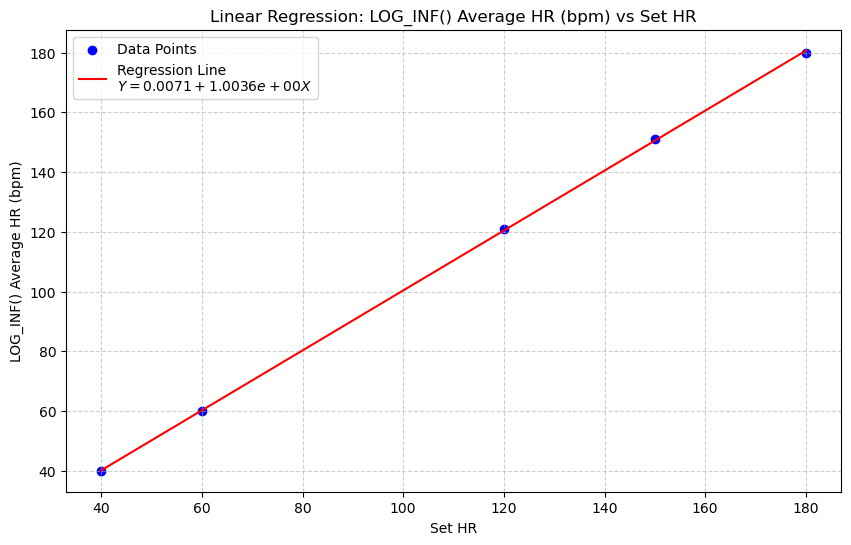

In [22]:
#Set Heart Rate vs LOG_INF Average HR (bpm)
X_COL_1_df2 = 'Set HR'
Y_COL_1_df2 = 'LOG_INF() Average HR (bpm)'
run_regression_analysis_scipy(df2, X_COL_1_df2, Y_COL_1_df2)


Regression Analysis: BLE Average HR (bpm) (Y) vs Set HR (X)

Linear Regression Equation (R² = 0.9999):
BLE Average HR (bpm) = 0.0071 + 1.0036e+00 * Set HR

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | 0.0071  | -1.9086      | 1.9229      |
| Slope     | 1.0036e+00 | 9.8788e-01   | 1.0193e+00   |


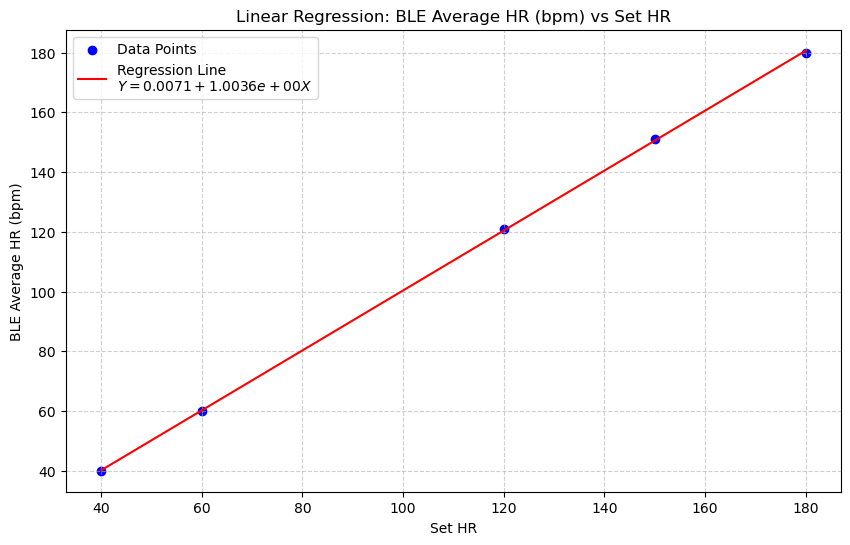

In [23]:
#Set Heart Rate vs BLE Average HR (bpm) 
X_COL_2_df2 = 'Set HR'
Y_COL_2_df2 = 'BLE Average HR (bpm)'
run_regression_analysis_scipy(df2, X_COL_2_df2, Y_COL_2_df2)


Regression Analysis: Scope Blink HR (bpm) (Y) vs Set HR (X)

Linear Regression Equation (R² = 0.9999):
Scope Blink HR (bpm) = -0.6600 + 1.0092e+00 * Set HR

95% Confidence Intervals (using SciPy's t-distribution):
| Parameter | Value       | 95% Lower Bound | 95% Upper Bound |
|:----------|:------------|:----------------|:----------------|
| Intercept | -0.6600  | -2.9324      | 1.6124      |
| Slope     | 1.0092e+00 | 9.9058e-01   | 1.0278e+00   |


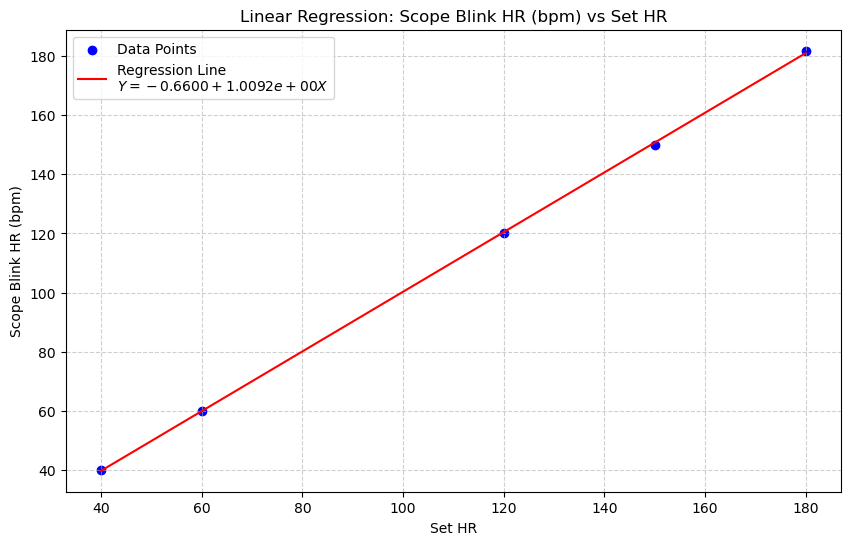

In [25]:
#Set Heart Rate vs Scope Blink HR (bpm) 
X_COL_3_df2 = 'Set HR'
Y_COL_3_df2 = 'Scope Blink HR (bpm)'
run_regression_analysis_scipy(df2, X_COL_3_df2, Y_COL_3_df2)

### Discussion
Performing linear regression analysis on the recorded heart rate values vs the set heart rate for all three output types yielded near perfect fits with R^2 very close to 1.0. The slopes for all three output types were approximately 1, meaning the ouput is doing a good job of mirroring the input. Regarding the scope blink duty cycle, values are tightly grouped around 25% across all heart rates, with an average value of 25.15%, verifying that the intended duty cycle was hit. 

## Section 3: Temperature Sensor Measurement

### Methods

To validate the temperature sensing capabilities of my script, I measured temperature in three different states: Out on a table in the lab, a hot condition on the same table, and a cold condition on the same table. The hot and cold conditions were created by breathing out hot and cold air for three seconds before taking a measurement. The LOG_INF statement was evaluated to see if temperature changes and the BLE measurement was checked to see if the value was the same, but rounded, as in my script the BLE reported temperature is rounded to the nearest int. 

### Results

In [27]:
# Load the data
df3 = pd.read_csv("final_temp_data.csv")

# Display the full data table
print("\nFull Data Table:")
print(df3.to_markdown(index=False, numalign="left", stralign="left"))


Full Data Table:
| Location   | Description                                             | LOG_INF Measurement (Deg C)   | BLE Mesurement (Deg C)   |
|:-----------|:--------------------------------------------------------|:------------------------------|:-------------------------|
| 1          | Bench in lab                                            | 25.94                         | 26                       |
| 2          | Bench in lab after breathing hot air for three seconds  | 27.25                         | 27                       |
| 3          | Bench in lab after breathing cold air for three seconds | 23.44                         | 23                       |


### Discussion
As seen above, the relative temperature changes are reflective of the hot, cold, or base state, with temp going up in the hot condition, and down in the cold condition. Additionally, all three measurments are grouped around 20-25 degrees C, which is approximately room temperature and is a reasonable value to be reading, indicating that the sensor is most likely working.